# Taller · Destilación en pequeño
**Un LLM grande (profesor, API de OpenAI) enseña a un modelo de 135 M parámetros (estudiante) que corre en tu CPU.**

Máster en IA · UAI · Tópicos Avanzados en IA 2

Taller de **15 horas en clases, entrega individual** (ver `Guia_Taller_Destilacion.pdf`). Este notebook recorre el ciclo técnico: una corrida completa toma **8–15 minutos** en un notebook sin GPU, y lo repetirás con tu propio dominio y distintos ajustes a lo largo de los bloques.

| Etapa | Qué pasa |
|---|---|
| 1 | Configurar: leer `.env`, elegir profesor (OpenAI u offline) y dispositivo |
| 2 | El profesor escribe preguntas y respuestas (entrenamiento + examen) |
| 3 | Cargar el estudiante pequeño y agregarle adaptadores LoRA |
| 4 | Examen **antes** de entrenar: el juez califica de 1 a 10 |
| 5 | Entrenar (SFT con LoRA) sobre las respuestas del profesor |
| 6 | Examen **después** + gráfico + ejemplos lado a lado |

> Sin clave de OpenAI o sin internet: en la celda 1 cambia `SIN_INTERNET = True`. Todo corre igual con un profesor simulado y un modelo diminuto local.

## 1 · Configurar

In [1]:
SIN_INTERNET = False        # True = sin clave ni descargas (profesor simulado + modelo diminuto)
ESTUDIANTE   = None         # None = HuggingFaceTB/SmolLM2-135M-Instruct · otra opción: "HuggingFaceTB/SmolLM2-360M-Instruct"

import destila as D
cfg = D.configurar(sin_internet=SIN_INTERNET, estudiante=ESTUDIANTE)
profesor = D.ProfesorOffline(cfg) if cfg["profesor_modo"] == "offline" else D.Profesor(cfg)
{k: ("***" if k == "api_key" else v) for k, v in cfg.items()}   # muestra cfg sin la clave

✔ Configuración: profesor = openai (gpt-6-luna) · estudiante = HuggingFaceTB/SmolLM2-135M-Instruct · dispositivo = cpu


{'dominio': 'asistente que explica conceptos de inteligencia artificial generativa a ejecutivos de empresas chilenas, con ejemplos de negocio',
 'temas': ['Fundamentos de LLM',
  'Ingeniería de prompts',
  'RAG',
  'Agentes de IA',
  'Ajuste fino',
  'Evaluación y LLMOps'],
 'idioma': 'English',
 'n_entrenamiento': 60,
 'n_examen': 12,
 'epocas': 3,
 'lote': 4,
 'tasa_aprendizaje': 0.0005,
 'lora_r': 16,
 'max_tokens_ejemplo': 320,
 'max_tokens_respuesta': 120,
 'max_palabras_profesor': 90,
 'estudiante': 'HuggingFaceTB/SmolLM2-135M-Instruct',
 'profesor': 'gpt-6-luna',
 'juez': 'gpt-6-luna',
 'semilla': 42,
 'api_key': '***',
 'sin_internet': False,
 'profesor_modo': 'openai',
 'dispositivo': 'cpu'}

**Para discutir:** ¿qué parámetros de `cfg` cambiarías para tu propio caso de negocio? El dominio y los temas son lo primero (`D.CONFIG` en `destila.py`).

## 2 · El profesor genera los datos
El profesor escribe preguntas por tema y luego las responde. Una parte se reserva como **examen fijo**: nunca se entrena con ella, para que la nota antes/después sea comparable.

In [2]:
entrenamiento, examen = D.generar_datos(cfg, profesor)
import pandas as pd
pd.DataFrame(entrenamiento).head(5)

✔ Datos existentes reutilizados: 60 de entrenamiento · 12 de examen (borra datos/ para regenerar)


,tema,pregunta,respuesta
0,Agentes de IA,How can executives measure whether an AI agent...,Measure outcomes against a pre-agent baseline ...
1,Ajuste fino,What does fine-tuning a generative AI model ac...,Fine-tuning updates a model’s internal weights...
2,Ingeniería de prompts,Can you show how to structure a prompt that su...,Use this prompt template:\n\n“You are a sales ...
3,Ajuste fino,If we fine-tune a model on outdated procedures...,If procedures are embedded through fine-tuning...
4,RAG,Could a mining company in Chile use RAG to hel...,Yes. A Chilean mining company could use retrie...


## 3 · Cargar el estudiante
SmolLM2-135M-Instruct: arquitectura Llama, 135 M parámetros, 270 MB. LoRA agrega matrices pequeñas entrenables; el modelo base queda congelado.

In [3]:
estudiante = D.cargar_estudiante(cfg)

→ Cargando estudiante 'HuggingFaceTB/SmolLM2-135M-Instruct' (la primera vez se descarga desde Hugging Face)…


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

✔ Estudiante listo: 135 M parámetros · LoRA entrena 4.88 M (3.6 %)


## 4 · Examen ANTES de entrenar
El estudiante responde el examen y el juez (el mismo profesor, con una rúbrica) califica cada respuesta de 1 a 10 comparándola con la referencia.

In [4]:
antes = D.evaluar(cfg, estudiante, profesor, examen, "antes")
pd.DataFrame(antes["detalle"])[["tema", "pregunta", "respuesta_estudiante", "nota", "comentario"]].head(6)

→ [antes] el estudiante responde 12 preguntas…


→ [antes] el juez califica…


✔ [antes] nota media 2/10 · aprobación 0% · 69.0 s


,tema,pregunta,respuesta_estudiante,nota,comentario
0,Ajuste fino,How does fine-tuning compare with retrieval-au...,Fine-tuning is a technique used to improve the...,2,La respuesta describe incorrectamente RAG como...
1,Ingeniería de prompts,What are common prompt-writing mistakes that l...,When it comes to writing a response for a user...,2,La respuesta está incompleta y contiene afirma...
2,RAG,How do we measure whether a RAG system is retr...,Measuring the effectiveness of a RAG system ca...,2,Menciona métricas generales de precisión y rec...
3,Agentes de IA,Can an AI agent reliably handle supplier invoi...,An AI agent can be trained to perform various ...,2,La respuesta se desvía hacia pagos y consultas...
4,Fundamentos de LLM,"Can an LLM understand a customer’s intent, or ...",An LLM (Licensed to Lend) can only match the p...,1,"La respuesta inventa una expansión de «LLM», c..."
5,Ingeniería de prompts,When should we use a prompt template instead o...,Using a prompt template rather than writing a ...,3,La respuesta apenas apunta a usar plantillas p...


## 5 · Entrenar
Ajuste fino supervisado: el modelo aprende a producir la **respuesta** del profesor (la pregunta se enmascara con −100 y no cuenta en la pérdida).

In [5]:
historial = D.entrenar(cfg, estudiante, entrenamiento)

→ Entrenando: 60 ejemplos · 3 épocas · 45 pasos · lote 4


   época 1 · paso 5/45 · pérdida 3.574 · 77 s


   época 1 · paso 10/45 · pérdida 3.626 · 154 s


   época 1 · paso 15/45 · pérdida 3.613 · 204 s


   época 2 · paso 20/45 · pérdida 3.144 · 257 s


...

   época 2 · paso 30/45 · pérdida 3.448 · 384 s


   época 3 · paso 35/45 · pérdida 2.870 · 460 s


   época 3 · paso 40/45 · pérdida 3.118 · 535 s


   época 3 · paso 45/45 · pérdida 2.902 · 585 s


✔ Entrenamiento listo en 586 s · pérdida 3.8173 → 2.902 · checkpoint en salidas/checkpoint


## 6 · Examen DESPUÉS y comparación

→ [despues] el estudiante responde 12 preguntas…


→ [despues] el juez califica…


✔ [despues] nota media 2.75/10 · aprobación 0% · 67.4 s


✔ Gráfico: C:\slm\taller-a\salidas\resultados.png · tabla y ejemplos: C:\slm\taller-a\salidas\resultados.md


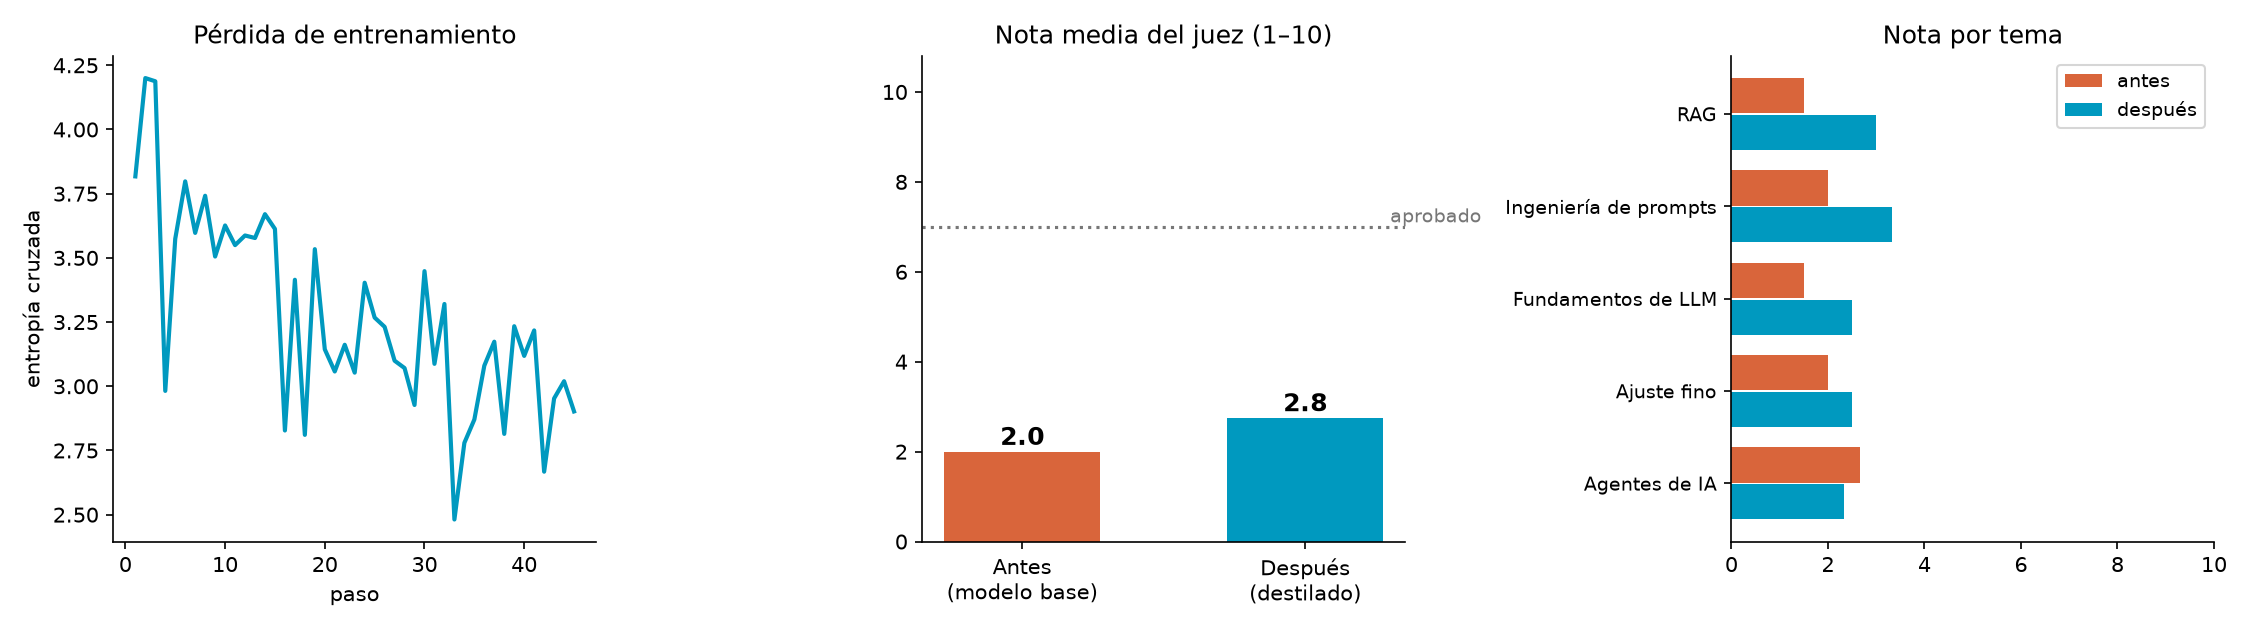

# Resultados del taller de destilación

| | Antes (base) | Después (destilado) |
|---|---|---|
| Nota media (1–10) | 2 | **2.75** |
| Aprobación (≥ 7) | 0% | **0%** |
| Pérdida de entrenamiento | 3.8173 | 2.902 |

Uso del profesor: 24 llamadas · 8,511 tokens de entrada · 3,523 de salida · ≈ US$ 0.0026

## Ejemplos lado a lado

**Pregunta:** How does fine-tuning compare with retrieval-augmented generation for answering questions about our company’s policies and products?

- Referencia del profesor: Fine-tuning teaches a model how to respond—such as using your company’s tone or following a specific workflow—but it is not the best way to keep policy and product facts current. Retrieval-augmented generation (RAG) searches approved company documents at question time and uses them to answer, making updates easier and answers easier to verify. For questions like “What is our return policy?”, RAG is usually the better choice. Fine-tuning can complement it when you also need consistent language or task behavior.
- Antes (nota 2): Fine-tuning is a technique used to improve the accuracy of responses by adjusting parameters or features that influence how well they capture relevant information from the user's input data. In contrast, retrieval-augmented generation (RAG) focuses on generating answers based solely on existing know
- Después (nota 2): Fine-tuning is a way to test the accuracy of answers against actual responses—for example, asking whether a policy will be enforced by law or not; then retraining it on new examples that match those rules. Retrieval-augmented generation can answer more complex queries but may require human review be

**Pregunta:** What are common prompt-writing mistakes that lead to vague, inaccurate, or overly confident answers?

- Referencia del profesor: Common mistakes include giving a vague task (“analyze our performance”) without defining the goal, audience, or success criteria; omitting key context such as market, time period, or source data; combining too many requests; using ambiguous terms; and failing to specify the desired format. Asking for current facts without providing sources can invite fabricated details. Leading questions, or demanding certainty when evidence is limited, can produce biased or overconfident answers. State assumptions, request evidence, and ask the model to flag uncertainty.
- Antes (nota 2): When it comes to writing a response for a user's query, there are several common pitfalls that can lead to unclear, inaccurate, or overly confident responses:

1. **Lack of specificity**: Providing too much information upfront without specifying the purpose or scope is crucial. Users often ask about
- Después (nota 5): Common mistake: Using a question as the sole basis for a response without checking its accuracy; using it only when asked—not enough context is needed; providing too much detail but not sufficient information; failing to test assumptions before testing results; including irrelevant details unless th

**Pregunta:** How do we measure whether a RAG system is retrieving the right information and giving reliable answers, rather than just sounding convincing?

- Referencia del profesor: Build a test set of real business questions with verified answers and source documents. Measure retrieval precision and recall: did the system find the right evidence, without burying it in irrelevant results? Score answer correctness, factual support by retrieved sources, and citation accuracy separately. Test whether it abstains when evidence is missing or conflicting. Have domain experts review edge cases, then monitor these measures and user-reported errors in production. Track task outcomes, not fluency: a polished answer without verifiable evidence is a failure.
- Antes (nota 2): Measuring the effectiveness of a RAG system can be challenging due to its subjective nature. However, there are several methods that can help evaluate the accuracy and reliability of a RAG system:

1. **Data quality checks**: Verify if the data used for training the model has been properly cleaned, 
- Después (nota 4): Use metrics such as accuracy (the percentage of relevant data retrieved), relevance—whether it’s useful for what you need to answer, consistency across sources, and human review)—and reliability: check that retrieval times match expected usage; don’t rely on vague or unsupported claims; test against

**Pregunta:** Can an AI agent reliably handle supplier invoices and purchase approvals, or should a human review every decision?

- Referencia del profesor: An AI agent can reliably automate routine checks—such as matching invoices to purchase orders, validating amounts and flagging missing information—if it uses approved systems, clear rules and audit logs. A human need not review every low-risk match. Escalate exceptions, high-value purchases, new suppliers, bank-detail changes and policy overrides for human approval. Keep approval limits and separation of duties in place, and regularly sample decisions to catch errors or drift.
- Antes (nota 2): An AI agent can be trained to perform various tasks such as invoice processing, order approval, payment handling, etc., but it cannot directly manage the actual process of receiving payments from suppliers due to its lack of knowledge about these processes. Therefore, humans would need to manually v
- Después (nota 3): An agent can process invoice receipts but cannot verify the accuracy of sales data; approve purchases only when approved by authorized parties—typically customers who have valid contracts with the vendor. Human reviewers check compliance, such as payment terms, delivery dates, and return policies. F

**Pregunta:** Can an LLM understand a customer’s intent, or is it mainly matching patterns in language? What does that distinction mean for a bank in Chile?

- Referencia del profesor: An LLM can often infer a customer’s likely intent from context, but it does so through learned language patterns—not human understanding. It can misread Chilean expressions, ambiguous requests, or unusual cases. For a Chilean bank, this makes it useful for routing queries, summarizing requests, or drafting answers, but risky as the sole decision-maker for credit, fraud, or complaints. Use local testing, privacy safeguards, clear escalation to staff, and human review for consequential decisions.
- Antes (nota 1): An LLM (Licensed to Lend) can only match the pattern of words used by customers when they refer to their account balance with another company. It doesn't have any knowledge about the context or meaning behind those terms; instead, it relies on linguistic similarity based solely on word frequency. Th
- Después (nota 2): An LLM can recognize the context of what customers say—whether they need help with something like checking account balances or making payments; whether their answer matches what someone else might ask (e.g., “Do you have any questions?”); how often they will hear from them; when they may be asked ag


In [6]:
despues = D.evaluar(cfg, estudiante, profesor, examen, "despues")
ruta = D.comparar(antes, despues, historial, profesor)
from IPython.display import Image, Markdown, display
display(Image(filename=str(ruta)))
display(Markdown((D.SALIDAS / "resultados.md").read_text(encoding="utf-8")))

## 7 · Conversa con tu modelo destilado
Compara con el modelo base (sin entrenar). Prueba también una pregunta **fuera** del dominio: ¿qué pasa?

In [7]:
D.chatear(estudiante, "Explain what LoRA is and what it is useful for in a bank.")

Tú › Explain what LoRA is and what it is useful for in a bank.



Destilado › LoRa stands for Low-Rate Automatic Translation. It’s a service that can translate documents from one language to another without human intervention—for example, translating a customer complaint into Spanish or French while the company still processes payments. LoRs work by sending small packets of text (called “messages”) through a network link with each document sent only when needed: no more than 10 seconds may be exchanged between customers and banks; they don’t require approval before delivery; and they use machine translation models trained on real-world examples rather than expensive human translations. They help reduce errors caused by



Base (sin entrenar) › LoRa (Low-Rate Wide Area Network) is a wireless communication technology that allows devices to communicate with each other over short distances without the need for traditional cellular networks or Wi-Fi routers. It's designed specifically for use within mobile applications such as smart home devices, fitness trackers, and IoT sensors.

In a bank setting, LoRa can be used to enable secure data transfer between different systems, including credit card processing, online banking, and payment gateways. This feature makes it ideal for transactions involving sensitive financial information like account balances, transaction history, and security codes. By using



In [8]:
D.chatear(estudiante, "What is a hallucination and how can I control it with RAG in a clinic?")

Tú › What is a hallucination and how can I control it with RAG in a clinic?



Destilado › A hallucination occurs when your brain misinterpres sensory information—like what’s real or false—and sends the wrong message to your body. For example: You might see someone who doesn’t really exist; hear voices that aren’t there; feel pain without touching something painful; or have vivid dreams about things you don’t know. Control hallucinations by asking them where they come from (e.g., “Where do these feelings originate?”) and whether their answers match reality. Use trained models like LIME for more accurate responses than human-annotated ones.



Base (sin entrenar) › A hallucination refers to the perception of one's own or another person's perceptions that aren't real. It occurs when your brain misinterprets sensory information from outside your body, often due to various factors such as hallucinations caused by stress, anxiety, sleep deprivation, or even visual stimuli like bright lights or colors.

In a clinical setting, controlling hallucinations requires a combination of techniques:

1. **Visualization**: Visualizing yourself in different environments helps you focus on what's happening inside your head rather than external distractions. This technique involves focusing on specific areas within your surroundings while keeping other distracting



## Plan de los cinco bloques y entrega
| Bloque | Objetivo | Hito |
|---|---|---|
| 1 | Instalar y correr el ciclo completo | `resultados.png` de la configuración por defecto |
| 2 | Tu dominio y tus datos (`D.CONFIG`, revisar 10 respuestas del profesor) | Secciones 1–2 del informe |
| 3 | Línea base y ≥ 3 experimentos (una variable por vez) | Tabla de experimentos |
| 4 | Auditar al juez (10 ítems a mano) y fijar la corrida final | Sección 5 del informe, `salidas/checkpoint` |
| 5 | Demostración de 5 min y reflexión | Informe PDF + carpeta del proyecto |

**Entrega individual:** informe PDF según `PLANTILLA_INFORME.md` (6–10 páginas) + carpeta del proyecto comprimida (sin `.env`).
Atraso: −1,5 puntos por día hasta nota 1,0. La rúbrica está en la guía.

> Consejo: cada vez que cambies el dominio o la cantidad de datos, borra la carpeta `datos/` para que el profesor los regenere. Guarda cada `salidas/` con un nombre distinto (`salidas_corrida1`, …) para no perder tus experimentos.